# 01 · Componentes, autocorrelación y estacionariedad

**Objetivo:** separar una serie en tendencia, estacionalidad y ruido; leer sus funciones de
autocorrelación (ACF/PACF) para identificar estructura; y entender por qué muchos modelos exigen
**estacionariedad** y cómo se consigue diferenciando.

Datos: CO₂ atmosférico en Mauna Loa (ppm), mensual, 1958–2001 (incluido en statsmodels).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
co2 = (
    sm.datasets.co2.load_pandas().data["co2"].resample("MS").mean().interpolate()
)  # mensual, 1958–2001
from applied_ts.autocorrelation import acf, difference, pacf
from applied_ts.decomposition import classical_decompose
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

## 1. Descomposición clásica

máx. |diferencia| con statsmodels: 0.0


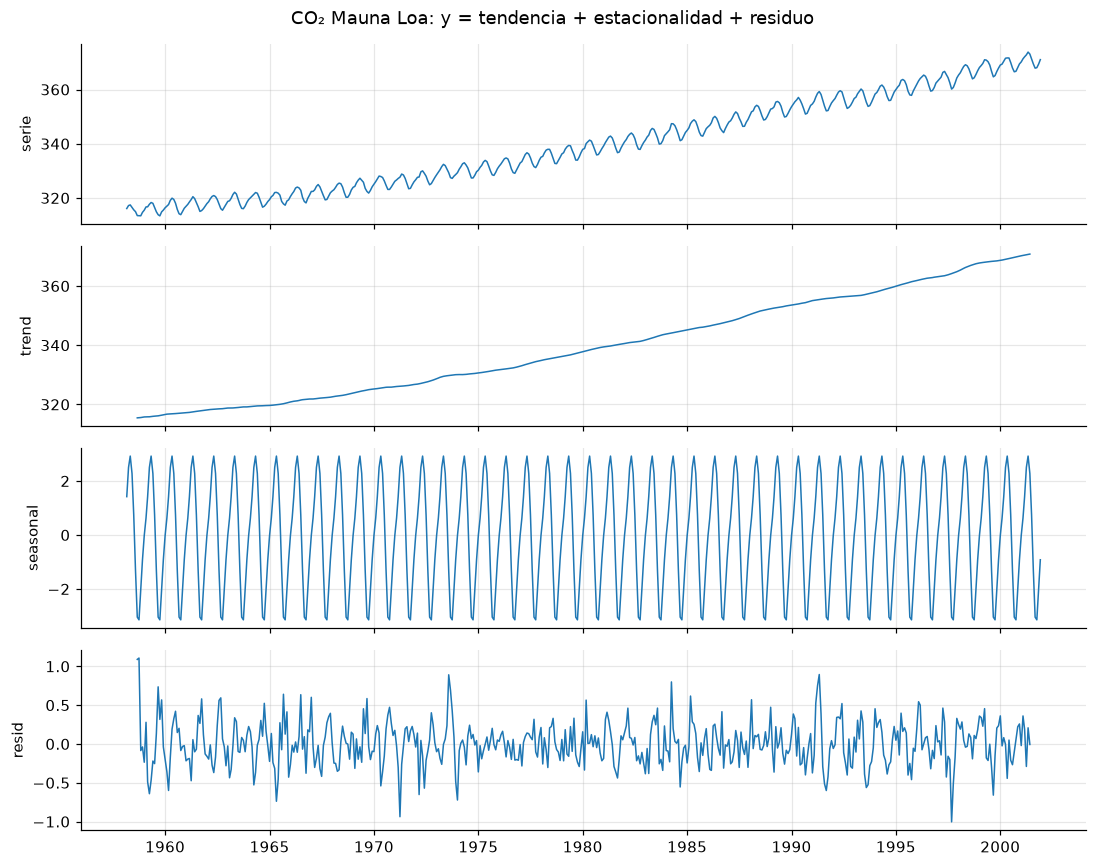

In [2]:
dec = classical_decompose(co2.to_numpy(), 12)
ref = seasonal_decompose(co2, period=12)
print("máx. |diferencia| con statsmodels:", np.nanmax(np.abs(dec["trend"] - ref.trend.to_numpy())))

fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
for ax, (name, values) in zip(axes, [("serie", co2.to_numpy()), *dec.items()], strict=True):
    ax.plot(co2.index, values, lw=1)
    ax.set_ylabel(name)
fig.suptitle("CO₂ Mauna Loa: y = tendencia + estacionalidad + residuo")
fig.tight_layout()

La tendencia es la media móvil centrada de 12 meses; la estacionalidad, el promedio por mes
del residuo sin tendencia. Amplitud estacional ≈ 6 ppm (la vegetación del hemisferio norte
absorbe CO₂ en verano).

## 2. Firmas de la ACF y la PACF

Procesos sintéticos para aprender a leerlas:
- **AR(2)**: la ACF decae gradualmente; la PACF se corta tras el rezago 2.
- **MA(1)**: la ACF se corta tras el rezago 1; la PACF decae.
- **Caminata aleatoria**: ACF casi 1 en todos los rezagos (no estacionaria).

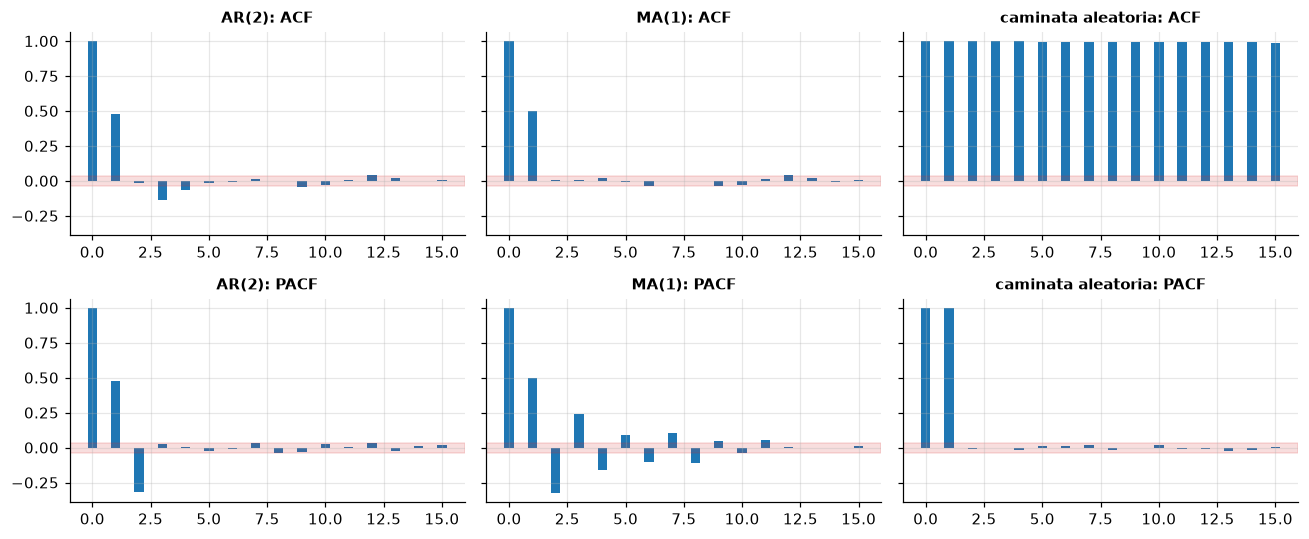

In [3]:
n = 3000
e = rng.normal(size=n)
ar2 = np.zeros(n)
for t in range(2, n):
    ar2[t] = 0.6 * ar2[t - 1] - 0.3 * ar2[t - 2] + e[t]
ma1 = e + 0.8 * np.r_[0, e[:-1]]
walk = np.cumsum(e)

fig, axes = plt.subplots(2, 3, figsize=(12, 5), sharey=True)
for col, (name, s) in enumerate([("AR(2)", ar2), ("MA(1)", ma1), ("caminata aleatoria", walk)]):
    for row, (fn, label) in enumerate([(acf, "ACF"), (pacf, "PACF")]):
        ax = axes[row, col]
        vals = fn(s, 15)
        ax.bar(range(16), vals, width=0.4)
        ax.axhspan(-1.96 / np.sqrt(n), 1.96 / np.sqrt(n), color="C3", alpha=0.15)
        ax.set_title(f"{name}: {label}", fontsize=10)
fig.tight_layout()

La banda roja es $\pm 1.96/\sqrt n$: lo que cabe esperar por azar en ruido blanco.

## 3. Estacionariedad y diferenciación

Una serie es (débilmente) estacionaria si su media, varianza y autocovarianzas no dependen del
tiempo. La prueba de Dickey–Fuller aumentada contrasta $H_0$: hay raíz unitaria (no estacionaria).

/var/folders/19/6n8svvf11154lmv9brnc3kkr0000gn/T/ipykernel_23036/629297680.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_adf = adfuller(s, autolag="AIC")[1]
/var/folders/19/6n8svvf11154lmv9brnc3kkr0000gn/T/ipykernel_23036/629297680.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_adf = adfuller(s, autolag="AIC")[1]
/var/folders/19/6n8svvf11154lmv9brnc3kkr00

original                     ADF p-valor = 0.999
∇ (primera diferencia)       ADF p-valor = 6.72e-05
∇₁₂ (diferencia estacional)  ADF p-valor = 0.000464
∇∇₁₂ (ambas)                 ADF p-valor = 2.27e-13


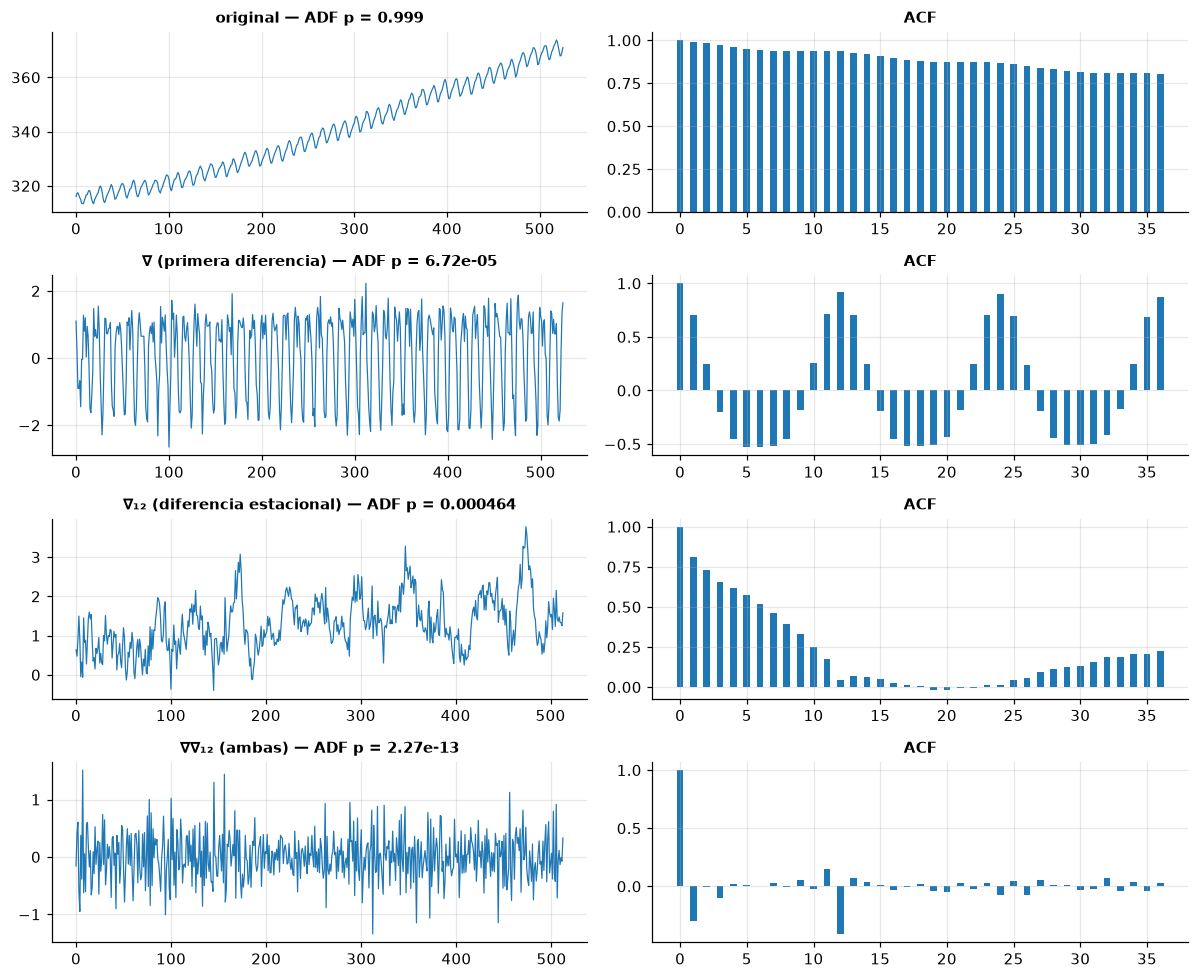

In [4]:
y = co2.to_numpy()
variants = {
    "original": y,
    "∇ (primera diferencia)": difference(y, 1),
    "∇₁₂ (diferencia estacional)": difference(y, 12),
    "∇∇₁₂ (ambas)": difference(difference(y, 12), 1),
}
fig, axes = plt.subplots(len(variants), 2, figsize=(11, 9))
for row, (name, s) in enumerate(variants.items()):
    p_adf = adfuller(s, autolag="AIC")[1]
    axes[row, 0].plot(s, lw=0.8)
    axes[row, 0].set_title(f"{name} — ADF p = {p_adf:.3g}", fontsize=10)
    axes[row, 1].bar(range(37), acf(s, 36), width=0.5)
    axes[row, 1].set_title("ACF", fontsize=10)
fig.tight_layout()
for name, s in variants.items():
    print(f"{name:<28} ADF p-valor = {adfuller(s, autolag='AIC')[1]:.3g}")

- La serie original no es estacionaria (ADF p ≈ 1).
- **∇ sola pasa la prueba ADF, pero no es suficiente:** su ACF sigue en ≈ 0.9 en los rezagos 12,
  24 y 36. ADF contrasta una raíz unitaria, no la estacionalidad: mirar siempre la ACF además del p-valor.
- **∇₁₂ sola** quita la estacionalidad pero deja una autocorrelación fuerte en el rezago 1 (≈ 0.8).
- **∇∇₁₂** deja una ACF con dos picos negativos, en 1 (≈ −0.3) y en 12 (≈ −0.4): la firma de
  términos MA regular y MA estacional. Es exactamente la estructura del modelo SARIMA(·,1,1)(0,1,1)₁₂
  que gana en el notebook 02.

## 4. Correlaciones espurias

Dos caminatas aleatorias **independientes** suelen mostrar correlaciones altas: la tendencia
estocástica de ambas domina. Diferenciar elimina el espejismo.

In [5]:
corr_levels, corr_diffs = [], []
for _ in range(500):
    a, b = np.cumsum(rng.normal(size=300)), np.cumsum(rng.normal(size=300))
    corr_levels.append(abs(np.corrcoef(a, b)[0, 1]))
    corr_diffs.append(abs(np.corrcoef(np.diff(a), np.diff(b))[0, 1]))
print(
    f"|correlación| media entre caminatas independientes: niveles {np.mean(corr_levels):.2f}, "
    f"diferencias {np.mean(corr_diffs):.2f}"
)
print(f"fracción con |r| > 0.5 en niveles: {np.mean(np.array(corr_levels) > 0.5):.0%}")

|correlación| media entre caminatas independientes: niveles 0.42, diferencias 0.05
fracción con |r| > 0.5 en niveles: 38%


## Para llevar

- Descomponer antes de modelar: ver qué parte es tendencia, ciclo y ruido.
- ACF/PACF identifican órdenes AR/MA y estacionalidad (picos en múltiplos del periodo).
- Diferenciar (∇, ∇ₘ) quita tendencia y estacionalidad; verificar con ADF y con la ACF.
- Nunca correlacionar o regresar series no estacionarias en niveles sin pensarlo dos veces.